<h1 align="center">Rwanda Maize–Urea Trial</h1>
<h2 align="center">7. Fertilizer Advisory & Decision Support</h2>

**Goal (Objective 2b):** turn the trial results into practical advice for Evergreen's extension teams:
1. Is the extra Urea **worth the money**?
2. **Where** should each combination be recommended?
3. A **decision-support tool** that extension staff can use without an analyst.

Code: [`src/maize/advisory.py`](../src/maize/advisory.py).

> **Data note.** The trial data is confidential and is not in this repository. The outputs shown were produced on the real data. If you run this notebook without it, it uses the synthetic sample in `01_Data/sample/` and the numbers will differ.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "02_Notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT / "src"))

import pandas as pd
from IPython.display import Image, display

from maize import config, data, advisory, analysis, plotting

pd.set_option("display.precision", 3)
pd.set_option("display.max_columns", 30)
MODE = config.data_mode()
OUT = config.output_paths(MODE)
print("Data source:", "confidential trial data (01_Data/raw)" if MODE == "raw" else "synthetic sample (01_Data/sample)")

Data source: confidential trial data (01_Data/raw)


In [2]:
_, combined = data.build_combined(MODE)
df = data.analysis_frame(combined)
te = analysis.treatment_effects(df)
interactions = [analysis.interaction_test(df, "meg_env"), analysis.interaction_test(df, "season")]
per_env = analysis.per_environment(df[~df["flag_implausible_yield"]].copy())
te["gains"][["label", "gain_vs_baseline", "ci_low", "ci_high", "p_holm"]]

,label,gain_vs_baseline,ci_low,ci_high,p_holm
0,"B: 100 kg/ha, planting + V6",0.144,-0.056,0.344,3.152e-01
1,"C: 100 kg/ha, V6 + V10",0.500,0.300,0.700,4.570e-06
2,"D: 100 kg/ha, all at V6",0.546,0.346,0.745,5.031e-07


## 1. Does the extra Urea pay?

The **value-cost ratio (VCR)** is the value of the extra maize divided by the cost of the extra 50 kg of Urea. A VCR of 2 or more is a common threshold for smallholder adoption, because it leaves a margin for risk and for costs not counted here (labour, transport).

Three price scenarios from published sources:

In [3]:
pd.DataFrame([{"scenario": s.name, "urea RWF/kg": s.urea_rwf_per_kg, "maize RWF/kg": s.maize_rwf_per_kg,
               "source": s.source} for s in config.PRICE_SCENARIOS])

,scenario,urea RWF/kg,maize RWF/kg,source
0,"Trial period, subsidised urea (2022)",754,237,Urea farmer price RWF 754/kg after subsidy (AG...
1,"Trial period, unsubsidised urea (2022)",1257,237,"Urea market price RWF 1,257/kg before subsidy ..."
2,"Current, subsidised urea (2026)",1090,400,"Urea farmer price RWF 1,090/kg after 45% subsi..."


In [4]:
econ = advisory.value_cost(te["gains"])
(econ.pivot(index="label", columns="scenario", values="vcr")
     .loc[[config.TREATMENT_LABELS[t] for t in config.TREATMENTS[1:]], [s.name for s in config.PRICE_SCENARIOS]])

scenario,"Trial period, subsidised urea (2022)","Trial period, unsubsidised urea (2022)","Current, subsidised urea (2026)"
label,,,
"B: 100 kg/ha, planting + V6",0.907,0.544,1.059
"C: 100 kg/ha, V6 + V10",3.143,1.886,3.670
"D: 100 kg/ha, all at V6",3.431,2.058,4.006


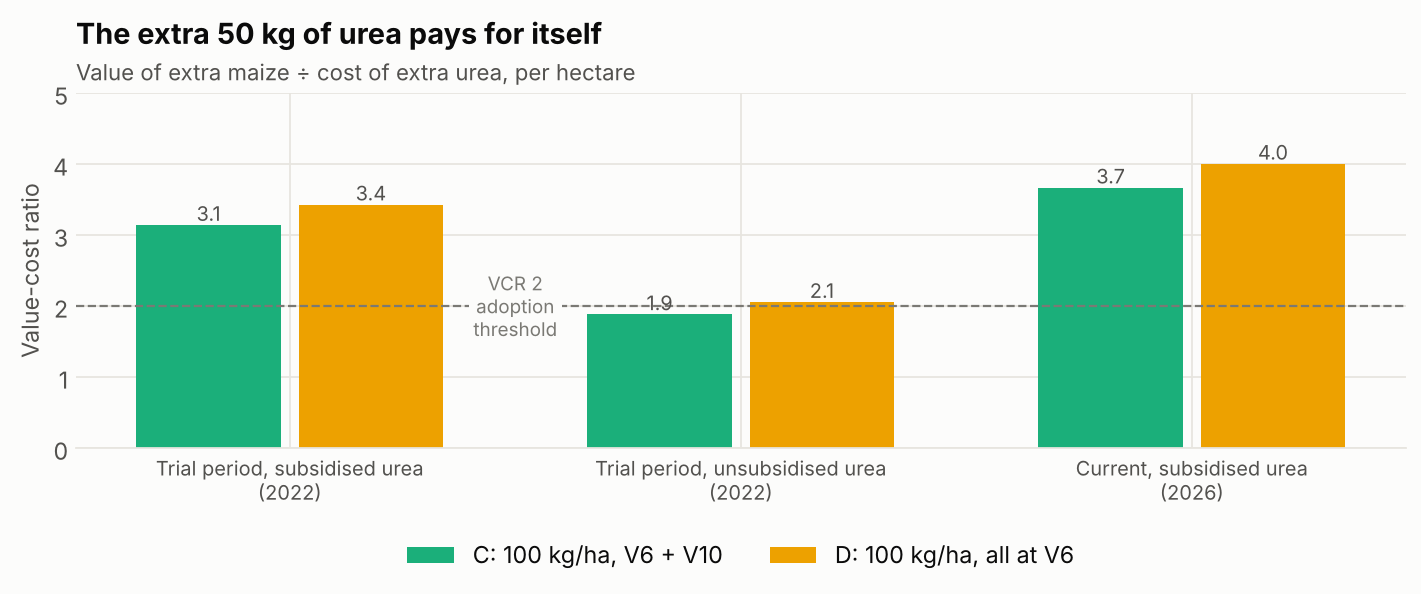

,scenario,extra_cost_rwf_ha,extra_value_rwf_ha,net_benefit_rwf_ha,vcr,vcr_at_ci_low,break_even_gain_tha
2,"Trial period, subsidised urea (2022)",37700,129352.105,91652.105,3.431,2.176,0.159
5,"Trial period, unsubsidised urea (2022)",62850,129352.105,66502.105,2.058,1.305,0.265
8,"Current, subsidised urea (2026)",54500,218315.789,163815.789,4.006,2.541,0.136


In [5]:
plotting.vcr_by_scenario(econ, OUT.figures / "value_cost_ratio.png")
display(Image(OUT.figures / "value_cost_ratio.png", width=760))
econ[econ["treatment"] == config.RECOMMENDED][["scenario", "extra_cost_rwf_ha", "extra_value_rwf_ha",
                                               "net_benefit_rwf_ha", "vcr", "vcr_at_ci_low", "break_even_gain_tha"]]

* **D pays clearly**: a VCR of 3.4 at trial-period prices and 4.0 at 2026 prices. Even at the lower end of its confidence interval it stays above 2 with subsidised Urea. It needs only about 0.16 t/ha extra maize to break even, against an estimated gain of 0.55.
* **Without the subsidy**, D only just clears the threshold (2.1) and C falls below it (1.9).
* **B never pays** (VCR ≈ 0.5–1.1).

The break-even rule: D stays above VCR 2 as long as the Urea price is below about **5.5×** the maize price.

## 2. Where should each combination be recommended?

Decision rule: recommend the highest-yielding treatment that is (1) significantly better than 50 kg/ha and (2) has VCR ≥ 2. Because effects do not differ by environment (p = 0.42), the pooled estimate is used everywhere, and the local estimate is shown as a check.

In [6]:
decision = advisory.decision_table(te["gains"], per_env, interactions)
decision[["meg_env", "n_fields", "recommended_label", "alternative_label", "avoid_label",
          "local_gain_tha", "local_ci_low", "local_ci_high", "local_agrees", "vcr"]]

,meg_env,n_fields,recommended_label,alternative_label,avoid_label,local_gain_tha,local_ci_low,local_ci_high,local_agrees,vcr
0,Highlands,142,"D: 100 kg/ha, all at V6","C: 100 kg/ha, V6 + V10","B: 100 kg/ha, planting + V6",0.486,0.277,0.694,True,3.431
1,Low-Mid-Dry,115,"D: 100 kg/ha, all at V6","C: 100 kg/ha, V6 + V10","B: 100 kg/ha, planting + V6",0.499,0.326,0.672,True,3.431
2,Low-Mid-Wet,77,"D: 100 kg/ha, all at V6","C: 100 kg/ha, V6 + V10","B: 100 kg/ha, planting + V6",0.805,0.611,0.999,True,3.431
3,Transitional,65,"D: 100 kg/ha, all at V6","C: 100 kg/ha, V6 + V10","B: 100 kg/ha, planting + V6",0.453,0.165,0.740,True,3.431


| Combination | Recommend? | Where | Why |
|---|---|---|---|
| **D: 100 kg/ha, all at V6** | **Default** | All four mega-environments | Highest yield everywhere; significant gain in each; VCR 3.4–4.0 |
| C: 100 kg/ha, V6 + V10 | Alternative | Where farmers prefer to split cost or labour; least suited to Transitional | Equivalent overall, but lower than D in Transitional, sensitive to one record, and needs an extra visit |
| B: 100 kg/ha, planting + V6 | No | – | Small gain that does not cover the extra Urea |
| A: 50 kg/ha, all at V6 | Fallback | If Urea is unsubsidised **and** maize prices fall | When D's VCR drops below 2 |

## 3. Decision-support tool

The tool is a single, offline HTML page with the estimates built in. A user chooses a mega-environment and enters local prices. The page applies the decision rule and shows the recommendation, expected gain, VCR, net benefit, and pooled vs. local estimates.

In [7]:
tool = OUT.tools / "index.html"
advisory.write_decision_tool(per_env, te["gains"], interactions, tool,
                             "confidential trial data" if MODE == "raw" else "synthetic sample data")
print("Decision tool written to", tool.relative_to(config.ROOT), f"({tool.stat().st_size / 1024:.0f} KB)")

Decision tool written to 03_Report/decision_tool/index.html (15 KB)


Open [`03_Report/decision_tool/index.html`](../03_Report/decision_tool/index.html) in a browser. It needs no internet connection or software.

## Final advice for Evergreen

1. **Recommend 100 kg/ha of Urea, all at V6**, in every mega-environment, with V6 + V10 as an accepted alternative.
2. **Drop the planting + V6 split.**
3. **Re-check profitability each season** with the tool as subsidies and maize prices change.
4. **Pair the Urea message with agronomy** (germination, timely planting, erosion control on slopes). Field conditions move yield far more than fertiliser timing does.
5. **Complete the rainfall and soil enrichment** and validate on new sites, especially short-rain (B) seasons in the east.

The full write-up is in the [analysis report](../03_Report/analysis_report.md).